In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from seaborn import heatmap
from pathlib import Path
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

print("Bibliotecas importadas com sucesso!")
print("Versão do Pandas:", pd.__version__)
print("Versão do NumPy:", np.__version__)

Bibliotecas importadas com sucesso!
Versão do Pandas: 3.0.5
Versão do NumPy: 2.5.2


In [2]:
# Set the path to the file you'd like to load
file_path = "channels/trending_channels.csv"
output_path = "/root/kaggle/"

candidates = [Path(output_path + file_path), Path(file_path.split("/")[1]), Path("../" + file_path.split("/")[1]), Path("/kaggle/input/" + file_path)]
local_file = next((file for file in candidates if file.exists()), None)

if local_file is None:
    from kagglehub import dataset_download
    path = Path(dataset_download(
        "shebilmsp/youtube-trending-dataset-updated-daily",
        file_path,
        output_dir=output_path
    ))
    del dataset_download

    candidates = sorted(path.rglob("*.csv"))
    if not candidates:
        raise FileNotFoundError("CSV não encontrado no download do Kaggle.")
    local_file = next((file for file in candidates if file.name.lower() == file_path.split("/")[1]), candidates[0])

print("Arquivo:", local_file)
df = pd.read_csv(local_file, dtype={
    "channel_id": str,
    "title": str,
    "description": str,
    "thumbnails": str,
    "custom_url": str,
    "default_language": str,
    "country": str,
    "subscriber_count": np.uint32,
    "video_count": np.uint32,
    "view_count": np.uint64,
    "banner_url": str,
    "keywords": str,
    "topics": str,
    "made_for_kids": bool,
    "privacy_status": str,
})

df.info()
df.head()

Arquivo: \root\kaggle\channels\trending_channels.csv
<class 'pandas.DataFrame'>
RangeIndex: 50769 entries, 0 to 50768
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   channel_id        50769 non-null  str   
 1   title             50769 non-null  str   
 2   description       34317 non-null  str   
 3   published_at      50769 non-null  str   
 4   thumbnails        50769 non-null  str   
 5   custom_url        37509 non-null  str   
 6   default_language  3327 non-null   str   
 7   country           29488 non-null  str   
 8   subscriber_count  50769 non-null  uint32
 9   video_count       50769 non-null  uint32
 10  view_count        50769 non-null  uint64
 11  banner_url        45638 non-null  str   
 12  keywords          24460 non-null  str   
 13  topics            47726 non-null  str   
 14  made_for_kids     50769 non-null  bool  
 15  privacy_status    50769 non-null  str   
dtypes: bool(1), str(

,channel_id,title,description,published_at,thumbnails,custom_url,default_language,country,subscriber_count,video_count,view_count,banner_url,keywords,topics,made_for_kids,privacy_status
0,UCsPMNatXCwqyUuJilBT73jg,CaylusBlox,i play roblox here\nsubscribe and join the CAY...,2024-08-02T07:21:37.449899Z,https://yt3.ggpht.com/z9psGKSPOr0-ztINI6uA9JCd...,@caylusblox,NaN,US,7990000,658,2494114083,https://yt3.googleusercontent.com/U6gW0sfTCF5_...,"caylus caylusblox ""caylus roblox"" ""caylus mine...","Simulation_video_game, Role-playing_video_game...",False,public
1,UCh5mLn90vUaB1PbRRx_AiaA,MoreSidemen,Welcome to the Official Sidemen 2nd Channel wh...,2018-02-01T21:48:49Z,https://yt3.ggpht.com/ytc/AIdro_kg8VuO1devOCTB...,@moresidemen,NaN,GB,9480000,1407,5851408261,https://yt3.googleusercontent.com/ThqnxdcrOtaX...,sidemen moresidemen sdmn,"Action_game, Video_game_culture, Entertainment...",False,public
2,UC1sELGmy5jp5fQUugmuYlXQ,Minecraft,This is the official YouTube channel of Minecr...,2010-12-21T21:36:46Z,https://yt3.ggpht.com/scvGT8SucZvs5yIkBBFQ0s0I...,@minecraft,NaN,SE,18000000,1313,3051711943,https://yt3.googleusercontent.com/bO4nn2OO4rZV...,Minecraft Mojang MINECON Gaming Microsoft Game...,"Action_game, Role-playing_video_game, Video_ga...",False,public
3,UCX4W0HfIH-26SVU8PLYf7iw,NiZ Series,NiZ series (Not In Zip series) is where creati...,2025-11-16T01:41:13.983468Z,https://yt3.ggpht.com/CXpIGC-U17XSaj2DNrwiwqex...,@nizseries,NaN,IN,926,28,909120,https://yt3.googleusercontent.com/ay_3_CB84HB7...,"trending trailer ai tvk ""not in zip"" ""think di...","Entertainment, Film",False,public
4,UCKFnbjBQDzzh002TMJcyuZA,Saregama Kannada,Saregama India Limited - the one-stop destinat...,2012-06-21T12:40:19Z,https://yt3.ggpht.com/LbelUn06UQA3VfF-RP_cXeh-...,@saregamakannada,NaN,IN,1420000,2477,692576948,https://yt3.googleusercontent.com/kywgIfYJgF-k...,"""saregama kannada"" ""Kannada cinema"" Chandanava...","Film, Pop_music, Music, Music_of_Asia, Enterta...",False,public


In [3]:
random_state = 42
split_samples_by = 10
target_column = "published_at"
assert target_column in df.columns, f"Coluna-alvo não encontrada no dataset: \"{target_column}\" em {list(df.columns)}"

df = df.drop(columns=["privacy_status", "thumbnails", "banner_url", "custom_url", "channel_id", "default_language", "keywords", "made_for_kids", "description", "topics"])
df = df.sample(n=len(df.values)//split_samples_by, random_state=random_state, replace=False)

df[target_column] = [target.split("-")[0] for target in df[target_column]]

str_columns = df.select_dtypes(include=["object", "string"])

for column in str_columns:
    df[column] = df[column].replace(np.nan, "")

x = df.drop(columns=target_column)
y = df[target_column]

display(x.info())
display(y.info())

assert y.notna().all(), display(
    "Existem valores ausentes nas amostras Y:",
    y[[not boolean for boolean in y.notna()]],
)
assert x.notna().all().all(), display(
    "Existem valores ausentes nas amostras X:",
    x[x.notna()].head(n=len(df))
)

display(
    x,
    y,
)

<class 'pandas.DataFrame'>
Index: 5076 entries, 30247 to 9006
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   title             5076 non-null   str   
 1   country           5076 non-null   str   
 2   subscriber_count  5076 non-null   uint32
 3   video_count       5076 non-null   uint32
 4   view_count        5076 non-null   uint64
dtypes: str(2), uint32(2), uint64(1)
memory usage: 198.3 KB


None

<class 'pandas.Series'>
Index: 5076 entries, 30247 to 9006
Series name: published_at
Non-Null Count  Dtype
--------------  -----
5076 non-null   str  
dtypes: str(1)
memory usage: 79.3 KB


None

,title,country,subscriber_count,video_count,view_count
30247,gnest_official,TH,2220000,749,86485367
45822,SpideyZoom1,IN,4070,117,1041595
46335,Release - Topic,,24,0,0
48038,Eryn Johns - Topic,,67,67,751697
13179,NYANSA COMEDY,GH,50700,200,7725045
...,...,...,...,...,...
17703,Dipssy,MX,15900000,1409,3248648151
37638,LosYonicsVEVO,,260000,176,412295872
21666,NOLAND_Easy,,8650,10,896872
11729,Арсен Шахунц,RU,714000,160,601305571


30247    2015
45822    2022
46335    2026
48038    2026
13179    2019
         ... 
17703    2016
37638    2015
21666    2024
11729    2012
9006     2020
Name: published_at, Length: 5076, dtype: str

In [4]:
print("Dimensões:", x.shape, "| Classes:", y.nunique())
print("Uso de memória das amostras cruas:", df.memory_usage().sum() / 1000, "KB")

display(
    (df.memory_usage() / 1000).rename("KB").to_frame().transpose(),
)

y_proportions = y.value_counts().sort_index().rename('count').to_frame()
y_proportions["proportions"] = (y.value_counts(normalize=True) * 100).to_frame()

print(f"\nClassificações e proporções da coluna-alvo \"{target_column}\":")
display(
    y_proportions,
)

Dimensões: (5076, 5) | Classes: 22
Uso de memória das amostras cruas: 243.648 KB


,Index,title,published_at,country,subscriber_count,video_count,view_count
KB,40.608,40.608,40.608,40.608,20.304,20.304,40.608



Classificações e proporções da coluna-alvo "published_at":


,count,proportions
published_at,,
2005,8,0.157604
2006,44,0.866824
2007,49,0.965327
2008,43,0.847124
2009,77,1.516942
2010,77,1.516942
2011,140,2.758077
2012,158,3.112687
2013,269,5.299448


Primeiras amostras de treino do DataFrame:


,title,country,subscriber_count,video_count,view_count
30247,gnest_official,TH,2220000,749,86485367
45822,SpideyZoom1,IN,4070,117,1041595
46335,Release - Topic,,24,0,0
48038,Eryn Johns - Topic,,67,67,751697
13179,NYANSA COMEDY,GH,50700,200,7725045



Amostras de treino transformadas do DataFrame:


,title,country,subscriber_count,video_count,view_count
30247,0,0,2220000,749,86485367
45822,1,1,4070,117,1041595
46335,2,2,24,0,0
48038,3,2,67,67,751697
13179,4,3,50700,200,7725045


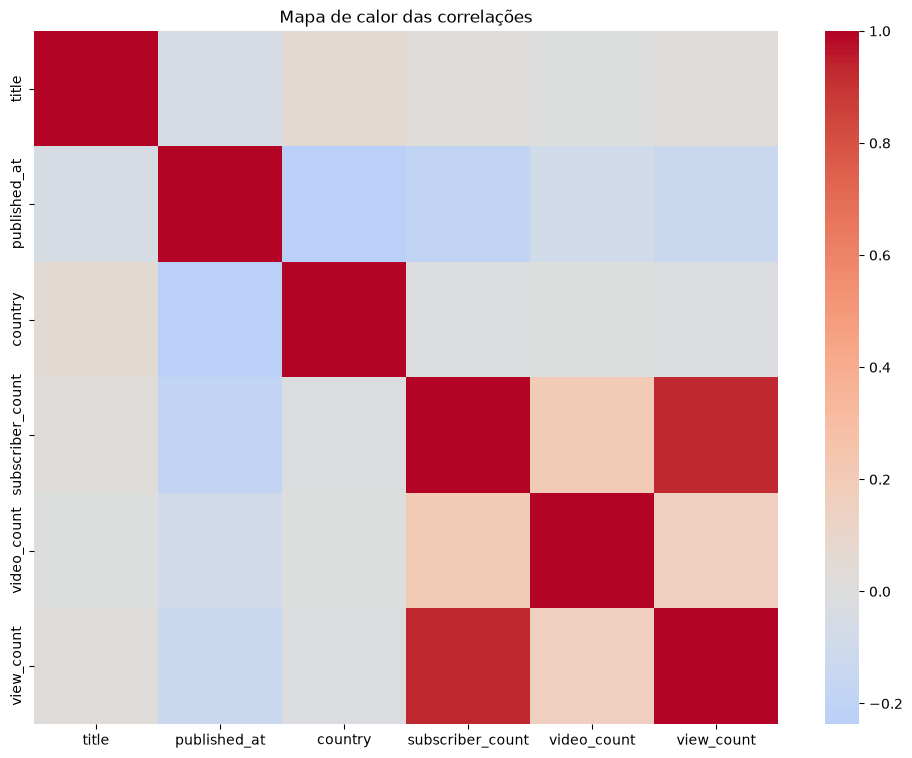

In [5]:
str_columns = x.select_dtypes(include=["object", "string"])
num_columns = list(x.select_dtypes(include='number').columns)

print(f"Primeiras amostras de treino do DataFrame:")
display(x.head())

for column in str_columns.columns:
    prepared_encoder = OneHotEncoder(handle_unknown="ignore", categories=[str_columns[column].unique()])
    df[column] = x[column] = prepared_encoder.fit_transform(pd.DataFrame(str_columns[column])).indices

print(f"\nAmostras de treino transformadas do DataFrame:")
display(x.head())

correlation = df.corr()
plt.figure(figsize=(12,9))
heatmap(correlation, cmap="coolwarm", center=0)
plt.title("Mapa de calor das correlações")
plt.show()

Colunas irrelevantes: {'title'}


,country,subscriber_count,video_count,view_count
30247,0,2220000,749,86485367
45822,1,4070,117,1041595
46335,2,24,0,0
48038,2,67,67,751697
13179,3,50700,200,7725045


Uso de memória das amostras filtradas: 142.128 KB


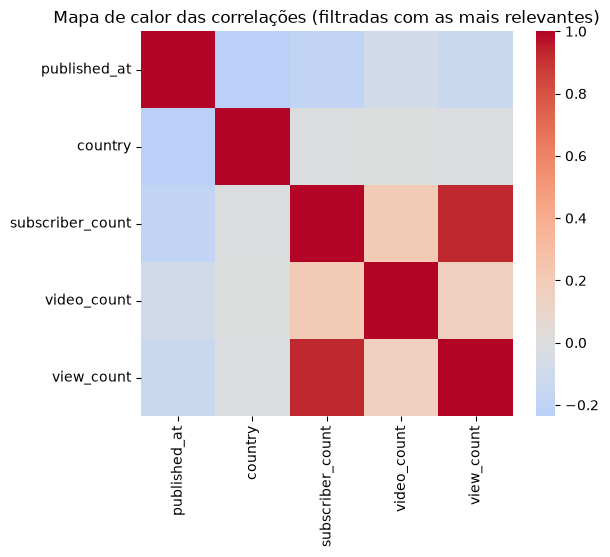

In [6]:
irrelevant_cols = set()
correlation_threshold = 0.1

for column_name in correlation.drop(columns=target_column).columns:
    column = correlation[column_name].drop(column_name)
    direct_correlation = column[column >= correlation_threshold]
    inverse_correlation = column[column <= -correlation_threshold]
    if len(direct_correlation) + len(inverse_correlation) == 0: irrelevant_cols.add(column_name)
print("Colunas irrelevantes:", irrelevant_cols)

x = x.drop(columns=irrelevant_cols)

correlation = df.drop(columns=irrelevant_cols).corr()
plt.figure(figsize=(6,5))
heatmap(correlation, annot=False, cmap="coolwarm", center=0)
plt.title("Mapa de calor das correlações (filtradas com as mais relevantes)")

display(x.head())
print(f"Uso de memória das amostras filtradas: {(x.memory_usage() / 1000).sum()} KB")
plt.show()

In [7]:
test_size = 0.7

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=random_state, stratify=y)

print("Treino:", x_train.shape, f"Uso de memória: {(x_train.memory_usage() / 1000).sum():.2f} KB")
print("Teste:", x_test.shape, f"Uso de memória: {x_test.memory_usage().sum() / 1000:.2f} KB")

print(f"\nImpacto de memória definitivo: {(x_train.memory_usage().sum() + x_test.memory_usage().sum()) / 1000:.2f} KB")

Treino: (1522, 4) Uso de memória: 42.62 KB
Teste: (3554, 4) Uso de memória: 99.51 KB

Impacto de memória definitivo: 142.13 KB


In [8]:
splits = 3
n_jobs = -1

params_dict = {
    # 'linear': {'svm__C':[1, 10, 100, 1000], 'svm__class_weight': [None, 'balanced']},
    # 'rbf': {'svm__C': [1, 10, 100], 'svm__gamma': ['auto', 'scale', 0.1, 1, 10], 'svm__class_weight': [None, 'balanced']},
    'poly': {'svm__C': [1, 10, 100], 'svm__gamma': ['auto', 'scale', 0.1, 1, 10], 'svm__coef0': [0, 1], 'svm__class_weight': [None, 'balanced']},
    'sigmoid': {'svm__C': [0.1, 1, 10], 'svm__gamma': ['auto', 'scale', 0.1, 1, 10], 'svm__coef0': [0, 1], 'svm__class_weight': [None, 'balanced']},
}

preprocessing = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(copy=False), num_columns),
        ('cat', OneHotEncoder(handle_unknown='ignore'), list(x.select_dtypes(include=["object", "string"]).columns))
    ]
)

cv = StratifiedKFold(n_splits=splits, shuffle=True, random_state=random_state)
results, cv_tables, predictions = [], {}, {}

for kernel, param_grid in params_dict.items():
    print(f'Executando {kernel.upper()}...')

    svm = SVC(kernel=kernel, cache_size=1000, random_state=random_state)
    pipeline = Pipeline([
        ('prep', preprocessing),
        ('svm', svm),
    ])

    search = GridSearchCV(pipeline, param_grid=param_grid, cv=cv, scoring=['accuracy', 'f1_macro', 'f1_micro'], n_jobs=n_jobs, refit='accuracy')

    start = time.monotonic()
    search.fit(x_train, y_train)
    elapsed = time.monotonic() - start
    print(f'Modelo treinado em {elapsed:.2f}s')

    y_pred = search.predict(x_test)

    predictions[kernel] = y_pred
    cv_tables[kernel] = pd.DataFrame(search.cv_results_).sort_values(by=['rank_test_accuracy', 'rank_test_f1_macro', 'rank_test_f1_micro'])
    results.append({
        'kernel': kernel,
        'cv_best_score': float(search.best_score_),
        'cv_accuracy': float(cv_tables[kernel]['mean_test_accuracy'][0]),
        'cv_f1_macro': float(cv_tables[kernel]['mean_test_f1_macro'][0]),
        'cv_f1_micro': float(cv_tables[kernel]['mean_test_f1_micro'][0]),
    })

    display(
        cv_tables[kernel][:5].transpose(),
        search.best_estimator_,
    )

Executando POLY...


c:\Users\estagiarioti.e01\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


Modelo treinado em 1597.59s


,49,44,29,48,39
mean_fit_time,201.945769,521.931814,38.734239,4.2679,31.697198
std_fit_time,279.770447,726.611548,53.424367,5.717493,43.637774
mean_score_time,0.061966,0.06196,0.076889,0.059939,0.055883
std_score_time,0.018086,0.004809,0.034206,0.002006,0.002741
param_svm__C,100,100,10,100,10
param_svm__class_weight,NaN,NaN,NaN,NaN,balanced
param_svm__coef0,1,0,1,1,1
param_svm__gamma,10,10,10,1,10
params,"{'svm__C': 100, 'svm__class_weight': None, 'sv...","{'svm__C': 100, 'svm__class_weight': None, 'sv...","{'svm__C': 10, 'svm__class_weight': None, 'svm...","{'svm__C': 100, 'svm__class_weight': None, 'sv...","{'svm__C': 10, 'svm__class_weight': 'balanced'..."
split0_test_accuracy,0.194882,0.185039,0.185039,0.206693,0.198819


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('svm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](22,)","['2005','2006','2007',...,'2024','2025','2026']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['country','subscriber_count','video_count','view_count']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

Executando SIGMOID...


c:\Users\estagiarioti.e01\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


Modelo treinado em 12.22s


,44,24,47,9,45
mean_fit_time,0.117978,0.135922,0.143341,0.187537,0.135505
std_fit_time,0.006522,0.011443,0.002133,0.010678,0.007452
mean_score_time,0.075713,0.085754,0.078435,0.104915,0.076084
std_score_time,0.013822,0.005885,0.002458,0.006605,0.000705
param_svm__C,10.0,1.0,10.0,0.1,10.0
param_svm__class_weight,NaN,NaN,NaN,NaN,NaN
param_svm__coef0,0,0,1,1,1
param_svm__gamma,10,10,0.1,10,auto
params,"{'svm__C': 10, 'svm__class_weight': None, 'svm...","{'svm__C': 1, 'svm__class_weight': None, 'svm_...","{'svm__C': 10, 'svm__class_weight': None, 'svm...","{'svm__C': 0.1, 'svm__class_weight': None, 'sv...","{'svm__C': 10, 'svm__class_weight': None, 'svm..."
split0_test_accuracy,0.167323,0.149606,0.147638,0.151575,0.149606


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('svm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](22,)","['2005','2006','2007',...,'2024','2025','2026']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['country','subscriber_count','video_count','view_count']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

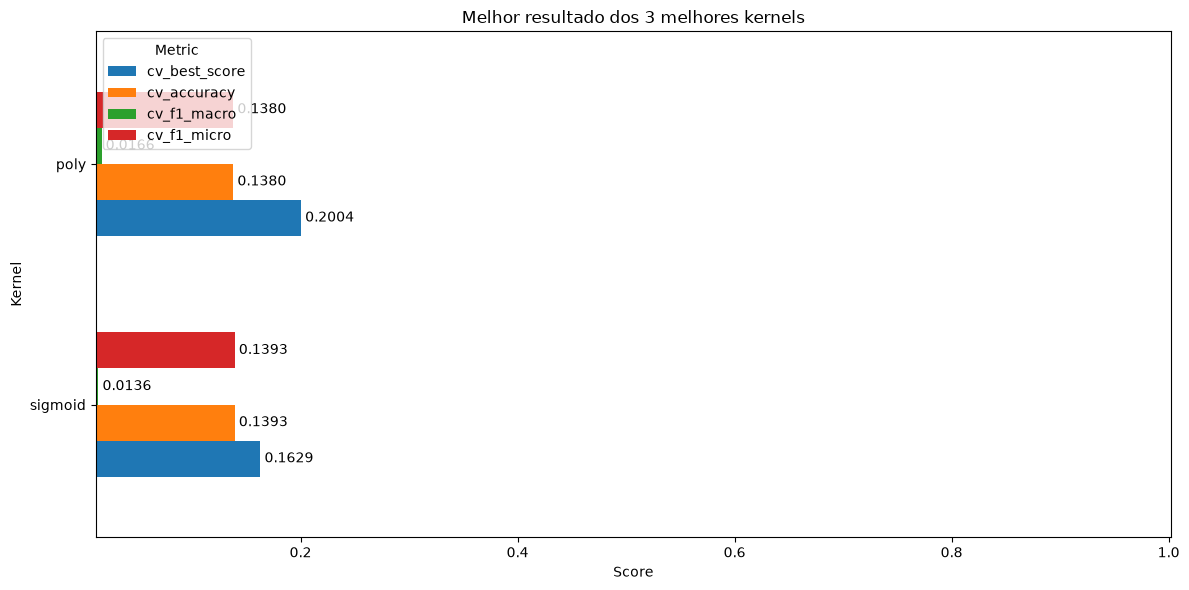

In [9]:
results_df = pd.DataFrame(results)

plot_data = results_df.set_index('kernel')[results_df.columns[1:]].sort_values(by=['cv_best_score', 'cv_f1_macro', 'cv_f1_micro'])[-3:]

ax = plot_data.plot(kind='barh', figsize=(12, 6), width=0.6)

ax.set(
    title="Melhor resultado dos 3 melhores kernels",
    xlabel="Score",
    ylabel="Kernel",
    xlim=(plot_data.min().min() - 0.0025, 1.0025),
)
ax.legend(loc='upper left', ncols=1, title='Metric')

for bars in ax.containers:
    ax.bar_label(bars, fmt='%.4f', padding=3)

plt.tight_layout()
plt.show()

ValueError: The number of FixedLocator locations (22), usually from a call to set_ticks, does not match the number of labels (1).

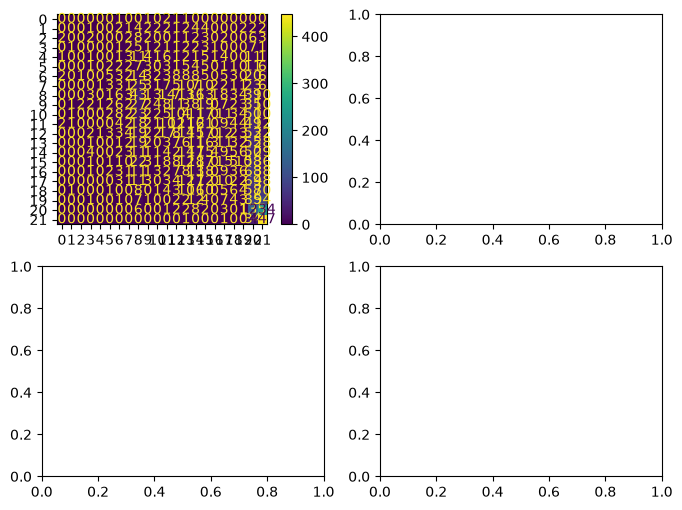

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(8, 6))

for (y_idx, x_idx), (svm_type, prediction) in zip(np.ndindex(axes.shape), predictions.items()):
    ax = axes[y_idx, x_idx]
    cm_disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, prediction), display_labels=[y.unique()])
    cm_disp.plot(ax=ax)
    cm_disp.ax_.set_title(f'Resultados para o kernel {svm_type.upper()}:')
    ax.set_xlabel("")
    ax.set_ylabel("")

fig.supxlabel(f"Predicted label ({len(x_test)} tests/{len(x)} total)", size=10)
fig.supylabel(f"True label ({len(x_test)}tests/{len(x)} total)", size=10)
plt.tight_layout()
plt.show()

In [ ]:
for svm_type, table in cv_tables.items():
    print(f'As piores performances para o SVM {svm_type.upper()}:')
    display(table.sort_values(by=['rank_test_accuracy', 'rank_test_f1_macro', 'rank_test_f1_micro'],ascending=False).head(7).transpose())